In [1]:
import os
import sys
from PIL import Image
import numpy as np
import torch
import random
import matplotlib.pyplot as plt

sys.path.append("src")
from viper.dataset import Dataset
from viper.predictor import Predictor

In [2]:
# Use the Dataset class with the location of your AFM images
# Pair of trace/retrace images should have the following naming convention:
# - <NAME>HeightTrace.txt
# - <NAME>HeightRetrace.txt
data_path = 'data/raw'
data = Dataset(data_path)
data.make_stripe_masks(idx=None)

Loaded Dataset (n, h, w): torch.Size([2, 256, 256])


In [3]:
# Model configuration
input_path    = "output"          # input folder where trained model was saved
model_name    = "N2N_tuto"        # name of your model (writing purposes)
architecture  = "n2n"             # one of: ["n2n", "unet", "vit", "attn_unet"]
device        = "mps"             # one of: ["mps", "cpu", "cuda"]

# Prediction configuration
crop_size = 32
stride = crop_size // 2

# Initialize model
pred = Predictor(arch=architecture, device=device, crop_size=crop_size)
pred.load(f"{input_path}/{model_name}.pt")

N2N: reducing depth from 5 to 3 to avoid collapse (img_size=32)
Loaded checkpoint from output/N2N_tuto.pt
-> norm_x_min: -0.8866437077522278
-> norm_scale: 2.425025701522827


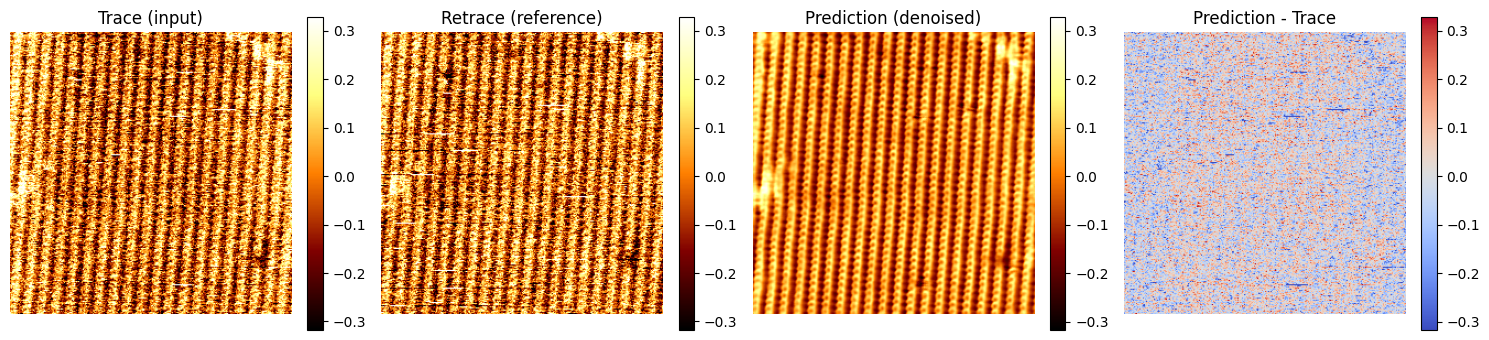

In [4]:
# Choose image index for prediction:
idx = 0

# Set Trace and Retrace images
X = data.imgs_x[idx]     # Trace image
y = data.imgs_y[idx]     # Retrace image

# Denoise
yh = pred.predict_image( # Denoised image
    X, stride=stride, batch_size=32)

# Create plot and save
save_name = data.names[idx].replace(".txt", f"_{model_name}")
_ = pred.compare(X, y, yh, output=save_name + ".png")
pred.write_image(yh, data.apix[idx], save_name + ".txt")

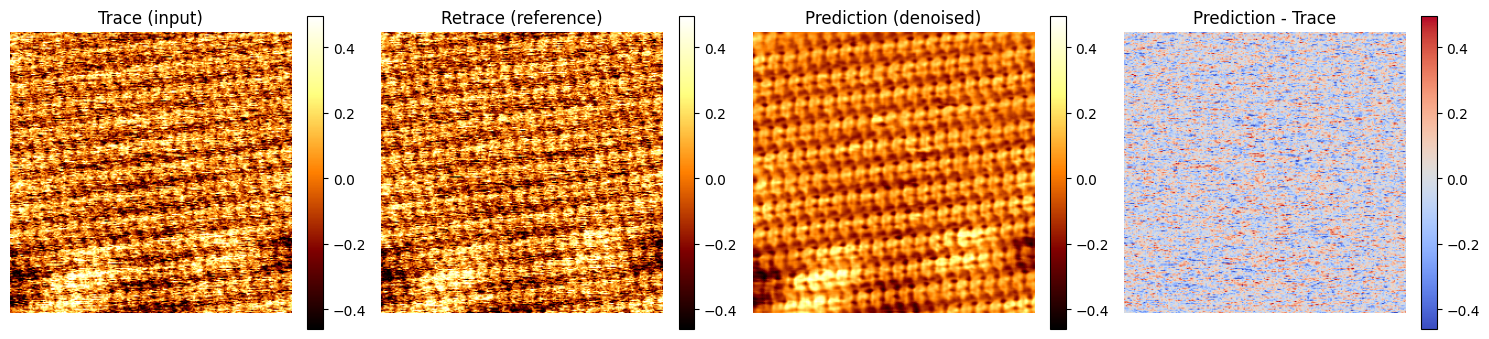

In [5]:
# Choose image index for prediction:
idx = 1

# Set Trace and Retrace images
X = data.imgs_x[idx]     # Trace image
y = data.imgs_y[idx]     # Retrace image

# Denoise
yh = pred.predict_image( # Denoised image
    X, stride=stride, batch_size=32)

# Create plot and save
save_name = data.names[idx].replace(".txt", f"_{model_name}")
_ = pred.compare(X, y, yh, output=save_name + ".png")
pred.write_image(yh, data.apix[idx], save_name + ".txt")